# 03 — H3 Design and Final Pretraining Binding

This notebook records the completed design, pre-execution defect discovery, correction,
canonical calibration, implementation binding, and dry-run gate. It does not launch or
evaluate H3 training. The final pretraining state is
`H3_FINAL_PRETRAINING_BINDING_COMPLETE__AWAITING_TRAINING_AUTHORIZATION`.

In [1]:
from pathlib import Path
import hashlib
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def discover_repo(start=None):
    candidates = []
    if start is not None:
        candidates.append(Path(start).resolve())
    candidates.extend([Path.cwd().resolve(), Path.cwd().resolve().parent])
    try:
        candidates.append(Path(__file__).resolve())
    except NameError:
        pass
    for candidate in candidates:
        current = candidate if candidate.is_dir() else candidate.parent
        for root in (current, *current.parents):
            if all((root / name).is_dir() for name in ("scripts", "reports", "manifests", "notebooks")):
                return root
    fallback = Path(r"D:/Softfors/jup")
    if all((fallback / name).is_dir() for name in ("scripts", "reports", "manifests", "notebooks")):
        return fallback
    raise RuntimeError("Repository root not found: expected scripts/, reports/, manifests/, notebooks/.")

ROOT = discover_repo()
AUDITS = ROOT / "reports" / "audits"
TABLES = ROOT / "reports" / "tables"

def load_json(relative):
    with (ROOT / relative).open("r", encoding="utf-8") as handle:
        return json.load(handle)

def read_csv(relative):
    return pd.read_csv(ROOT / relative)

def sha(relative):
    return hashlib.sha256((ROOT / relative).read_bytes()).hexdigest()

print("Repository root:", ROOT)
print("No training or inference is executed by this notebook.")

Repository root: D:\Softfors\jup
No training or inference is executed by this notebook.


In [2]:
correction = load_json("reports/audits/h3_proposal_supply_design_correction.json")
binding = load_json("reports/audits/h3_proposal_supply_final_pretraining_binding_v2.json")
protocol = load_json("reports/audits/h3_proposal_supply_design_protocol.json")
checklist = load_json("reports/audits/h3_proposal_supply_pre_execution_checklist.json")
selection = load_json("reports/audits/h3_proposal_supply_checkpoint_selection_rule.json")
launch = load_json("reports/audits/h3_training_launch_binding.json")
area_distribution = load_json("reports/tables/h3_v2_area_distribution.json")
area_audit = read_csv("reports/tables/h3_v2_component_area_audit.csv")
print("Axis:", binding["axis"])
print("Intervention:", binding["intervention_family"])

Axis: A_PROPOSAL_SUPPLY_RECALL_LIMITATION
Intervention: A_TARGET_SUPPORT_REDESIGN


## 1. Axis, intervention, defect, and correction

In [3]:
display(pd.DataFrame([
    ("selected axis", binding["axis"]),
    ("intervention family", binding["intervention_family"]),
    ("correct mechanistic wording", binding["intervention_wording"]),
    ("defective mapping", correction["supersedes"]["defective_formula"]),
    ("defect classification", correction["supersedes"]["defect_classification"]),
    ("corrected mapping", binding["corrected_mapping"]),
    ("A_ref", binding["authoritative_a_ref"]),
], columns=["item", "authoritative record"]))
print("Degeneracy proof: for every area_i >= 1, 4*sqrt(area_i) >= 4 >= 0.75, so clipping yields sigma=0.75.")

,item,authoritative record
0,selected axis,A_PROPOSAL_SUPPLY_RECALL_LIMITATION
1,intervention family,A_TARGET_SUPPORT_REDESIGN
2,correct mechanistic wording,FIXED_TARGET_SUPPORT_MAY_BE_MISMATCHED_TO_COMP...
3,defective mapping,"sigma_i = clip(scale_ref * sqrt(area_i), 0.35,..."
4,defect classification,PRE_EXECUTION_PARAMETERIZATION_DEFECT__ZERO_TR...
5,corrected mapping,sigma_i = clip(0.35 + 0.40 * sqrt(A128_i / A_r...
6,A_ref,13.0


Degeneracy proof: for every area_i >= 1, 4*sqrt(area_i) >= 4 >= 0.75, so clipping yields sigma=0.75.


## 2. Historical calibration reconciliation

In [4]:
cal = binding["authoritative_calibration_summary"]
display(pd.DataFrame([
    ("superseded A_ref=14.0", cal["superseded_calibrations"]["14.0"]),
    ("superseded A_ref=12.0", cal["superseded_calibrations"]["12.0"]),
    ("canonical TRAIN images", cal["population"]["n_images"]),
    ("canonical TRAIN components", cal["population"]["n_components"]),
    ("orphan quarantined", cal["population"]["orphan_samples_quarantined"]),
    ("zero-area components", cal["zero_area_count"]),
    ("authoritative A_ref", cal["A_ref"]),
    ("mapping", binding["corrected_mapping"]),
], columns=["item", "value"]))
print("Historical A_ref=14 and 12 are superseded because their relabeled populations violated component cardinality.")

,item,value
0,superseded A_ref=14.0,relabeled 128-space components (n=1149) — MERG...
1,superseded A_ref=12.0,relabeled direct 128-space (n=1078) — relabeli...
2,canonical TRAIN images,770
3,canonical TRAIN components,1161
4,orphan quarantined,[ef36ad8332b2f33882dc668a5b6846e5]
5,zero-area components,52
6,authoritative A_ref,13.0
7,mapping,sigma_i = clip(0.35 + 0.40 * sqrt(A128_i / A_r...


Historical A_ref=14 and 12 are superseded because their relabeled populations violated component cardinality.


## 3. Authoritative area distribution and sigma mapping

In [5]:
percentiles = pd.DataFrame([area_distribution["area128_percentiles"]])
display(percentiles)
print("Area distribution source: reports/tables/h3_v2_area_distribution.json")

,p0,p1,p5,p10,p25,p50,p75,p90,p95,p99,p100
0,0.0,0.0,1.0,1.0,2.0,5.0,13.0,40.0,73.0,152.0,278.0


Area distribution source: reports/tables/h3_v2_area_distribution.json


,metric,value
0,distinct sigma levels,14
1,fraction at floor 0.35,0.044789
2,fraction at ceiling 0.75,0.254953
3,median sigma,0.598069
4,TINY median sigma,0.46094
5,non-TINY median sigma,0.64352
6,TINY < non-TINY,True
7,all in bounds,True
8,non-degeneracy passed,True


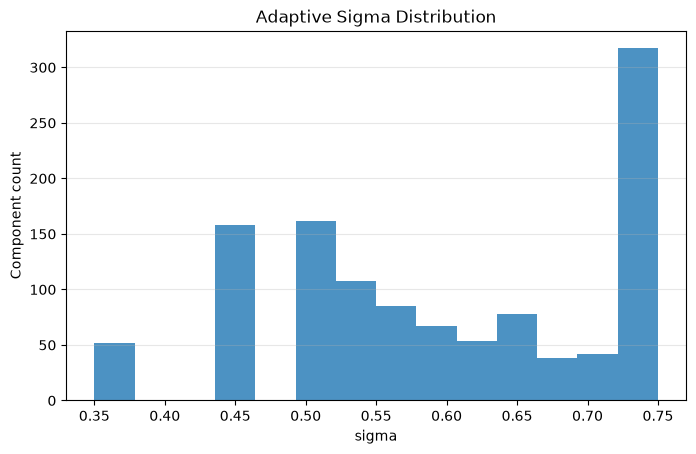

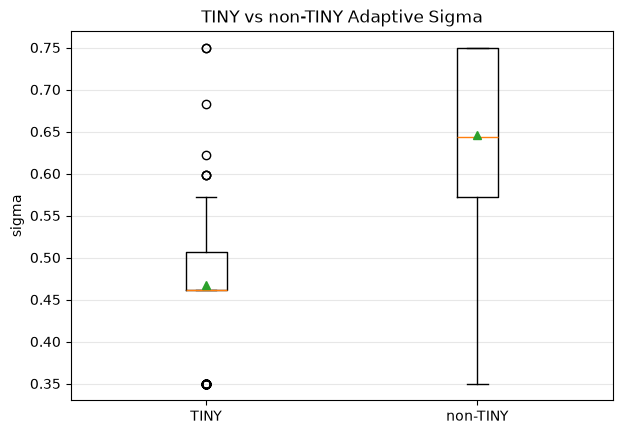

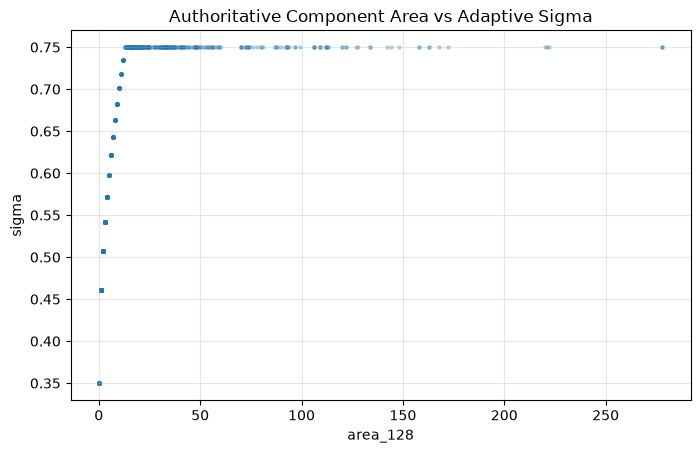

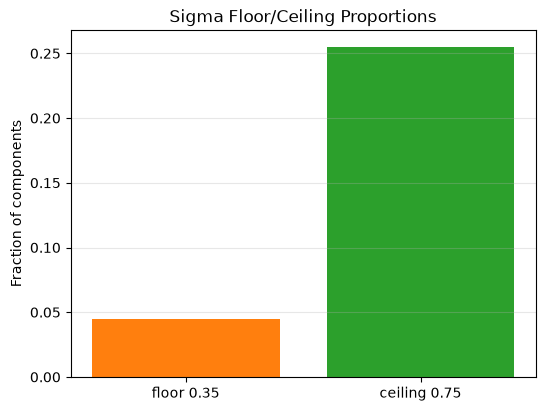

Display-only sigma medians: 0.4609400392450458 0.6435197542821371


In [6]:
sigma_stats = binding["authoritative_calibration_summary"]["non_degeneracy"]
sigma_table = pd.DataFrame([
    ("distinct sigma levels", sigma_stats["n_distinct_sigma_levels"]),
    ("fraction at floor 0.35", sigma_stats["frac_at_floor_0.35"]),
    ("fraction at ceiling 0.75", sigma_stats["frac_at_ceil_0.75"]),
    ("median sigma", sigma_stats["median_sigma"]),
    ("TINY median sigma", sigma_stats["tiny_median_sigma"]),
    ("non-TINY median sigma", sigma_stats["nontiny_median_sigma"]),
    ("TINY < non-TINY", sigma_stats["tiny_lt_nontiny"]),
    ("all in bounds", sigma_stats["all_in_bounds"]),
    ("non-degeneracy passed", sigma_stats["passed"]),
], columns=["metric", "value"])
display(sigma_table)
areas = area_audit.copy()
area_col = "area_128"
areas["sigma_display_only"] = (0.35 + 0.40 * (areas[area_col] / 13.0).pow(0.5)).clip(0.35, 0.75)
areas.loc[areas[area_col] == 0, "sigma_display_only"] = 0.35
tiny = areas[areas["size_stratum"] == "TINY"]["sigma_display_only"]
non_tiny = areas[areas["size_stratum"] != "TINY"]["sigma_display_only"]

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.hist(areas["sigma_display_only"], bins=14, color="tab:blue", alpha=0.8)
ax.set(title="Adaptive Sigma Distribution", xlabel="sigma", ylabel="Component count")
ax.grid(True, axis="y", alpha=0.3); plt.show()

fig, ax = plt.subplots(figsize=(7, 4.8))
ax.boxplot([tiny, non_tiny], tick_labels=["TINY", "non-TINY"], showmeans=True)
ax.set(title="TINY vs non-TINY Adaptive Sigma", ylabel="sigma")
ax.grid(True, axis="y", alpha=0.3); plt.show()

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.scatter(areas[area_col], areas["sigma_display_only"], s=5, alpha=0.25)
ax.set(title="Authoritative Component Area vs Adaptive Sigma",
       xlabel="area_128", ylabel="sigma")
ax.grid(True, alpha=0.3); plt.show()

floor = (areas["sigma_display_only"] == 0.35).mean()
ceil = (areas["sigma_display_only"] == 0.75).mean()
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.bar(["floor 0.35", "ceiling 0.75"], [floor, ceil], color=["tab:orange", "tab:green"])
ax.set(title="Sigma Floor/Ceiling Proportions", ylabel="Fraction of components")
ax.grid(True, axis="y", alpha=0.3); plt.show()
print("Display-only sigma medians:", tiny.median(), non_tiny.median())

## 4. Configuration and implementation reconciliation

In [7]:
reconciliation = binding["reconciliation_compliance_map"]
display(pd.DataFrame(list(reconciliation.items()), columns=["gate", "correction/status"]))
display(pd.DataFrame([
    ("loss", "CenterNetFocalLoss(alpha=2.0,beta=4.0,dice_weight=0.0)", "parent-identical"),
    ("proposal grid", "singleton decode: 0.10 / 0.20 / 5 / 0.30", "grid disabled"),
    ("population", "canonical 770 images / 1161 components", "one orphan quarantined"),
    ("selection", "(val_localization_recall, -val_loss)", "two-term tuple"),
], columns=["item", "final binding", "status"]))

,gate,correction/status
0,S1_config_loss_mismatch,RESOLVED — H3 YAML loss rewritten to CenterNet...
1,S2_eliminate_proposal_search,RESOLVED — H3 path evaluates EXACTLY ONE decod...
2,S3_train_population_identity,RESOLVED — bound to manifests/phase4_v3/train....
3,S4_component_cardinality,"RESOLVED — (sample_id, component_id) preserved..."
4,S5_area_distribution_recomputed,RESOLVED — reports/tables/h3_v2_area_distribut...
5,S6_a_ref_set,RESOLVED — authoritative A_ref = 13.0 (p75). S...
6,S7_non_degeneracy_reverified,PASS — calibration non_degeneracy.passed=true;...
7,S8_checkpoint_selection_audited,"PASS — exact tuple (val_localization_recall, -..."
8,S9_h3_config_execution_exact,RESOLVED — configs/kub/phase13b_localizer_h3_s...
9,S10_final_dry_run,PASS — training_steps=0; no optimizer step/epo...


,item,final binding,status
0,loss,"CenterNetFocalLoss(alpha=2.0,beta=4.0,dice_wei...",parent-identical
1,proposal grid,singleton decode: 0.10 / 0.20 / 5 / 0.30,grid disabled
2,population,canonical 770 images / 1161 components,one orphan quarantined
3,selection,"(val_localization_recall, -val_loss)",two-term tuple


## 5. Dry-run, backward compatibility, and final checklist

In [8]:
dry = binding["dry_run_result"]
display(pd.DataFrame([
    ("training steps executed", dry["training_steps_executed"]),
    ("config resolves", dry["config_resolves"]),
    ("singleton decode", dry["proposal_configurations_evaluated_per_epoch"]),
    ("selection tuple", dry["checkpoint_selection"]),
    ("loss", dry["loss"]),
    ("optimizer", dry["optimizer"]),
    ("scheduler", dry["scheduler"]),
    ("model param count", dry["model_param_count"]),
    ("manifests resolved", dry["manifests_resolved"]),
], columns=["dry-run item", "value"]))
display(pd.DataFrame([
    (item["id"], item["status"], item["item"])
    for item in checklist["checklist"] if item["id"] in {"C12", "C13", "C14", "C15"}
], columns=["check", "status", "definition"]))
print("Backward compatibility:", correction["backward_compatibility_and_h3_branch_tests"]["result"])

,dry-run item,value
0,training steps executed,0
1,config resolves,True
2,singleton decode,1
3,selection tuple,"{'rule': 'max_localization_recall', 'tuple': [..."
4,loss,"{'type': 'CenterNetFocalLoss', 'alpha': 2.0, '..."
5,optimizer,"{'type': 'AdamW', 'lr': 0.0001, 'weight_decay'..."
6,scheduler,"{'type': 'CosineAnnealingLR', 'T_max': 100, 'p..."
7,model param count,482449
8,manifests resolved,True


,check,status,definition
0,C12,PASS__FINAL_IMPLEMENTATION_VERIFIED,Apply code change (C2/C3) with the CORRECTED n...
1,C13,PENDING__SUPERVISOR_TRAINING_AUTHORIZATION,Supervisor authorizes H3 TRAINING (current tas...
2,C14,PASS__CORRECTION_APPLIED_AND_VERIFIED,Pre-execution parameterization defect (sigma_i...
3,C15,PASS__CONFIG_AND_CALIBRATION_RECONCILED,Config and calibration RECONCILED: H3 YAML los...


Backward compatibility: 12 passed


## 6. Complete implementation and manifest provenance

In [9]:
impl = binding["implementation_sha256"]
impl_table = pd.DataFrame([{"artifact": k, "SHA-256": v, "role": "implementation binding"} for k, v in impl.items()])
display(impl_table)
manifest_table = pd.DataFrame([{"artifact": k, "SHA-256": v, "role": "manifest binding"} for k, v in binding["manifest_bindings"].items()])
display(manifest_table)
frozen_table = pd.DataFrame([
    {"artifact": v["path"], "SHA-256": v["sha256"], "role": v["role"]}
    for v in binding["frozen_checkpoint_bindings"].values() if isinstance(v, dict) and "path" in v
])
display(frozen_table)
assert binding["authoritative_a_ref"] == 13.0
assert dry["training_steps_executed"] == 0
assert checklist["current_status"] == "H3_FINAL_PRETRAINING_BINDING_COMPLETE__AWAITING_TRAINING_AUTHORIZATION"
print("Phase 15: NOT_STARTED_AND_NOT_AUTHORIZED; TEST: CLOSED")

,artifact,SHA-256,role
0,src/inference/heatmap_targets.py,4fe01377b5fb2f15377fda37ef2114a04185fa44a6dace...,implementation binding
1,src/data/kub_localizer_dataset.py,b1c4645f8860d557ffc6cb145c224a7ddb5d804e558147...,implementation binding
2,src/training/clean_v3_selection.py,807a70181c1f0da7481a26f1d06e1a1f2ca21dd0e93d44...,implementation binding
3,scripts/training/train_phase13b_localizer.py,37b64310d38222310ce060803e37d17e4b6916ce7c522d...,implementation binding
4,tests/test_h3_size_adaptive_sigma.py,57094021876284e14449804f0a70ca5cfe62062612a5de...,implementation binding
5,scripts/audit/h3_calibrate_size_adaptive_sigma...,6c3eb477db3d74d75aa14b7182b11d6113204b58bbfb93...,implementation binding
6,configs/kub/phase13b_localizer_h3_size_adaptiv...,320a367068b6bec4ea357ebea4bca1460db2c7f7a435f1...,implementation binding


,artifact,SHA-256,role
0,manifests/phase4_v3/train.csv,28702fc3a5ff8b950db372f03232d335e3a30b1fc2f21d...,manifest binding
1,manifests/phase4_v3/val.csv,082c80b2bda63fd73f371f109c34643adf01edaead9216...,manifest binding


,artifact,SHA-256,role
0,checkpoints/phase13b_kub_localizer_r512_h128_s...,7673c34a2f2c86eca2e45c1bc6abe77842d17cd09f122f...,PARENT localizer — target-generation code rede...
1,checkpoints/phase14_kub_refiner_unet_a3_256_se...,2e09e3a9c39c731687db1a9fef0c80881ed6235e4cda07...,Stage-4D regional refiner (downstream eval)
2,checkpoints/phase10_kub_unetpp_seed42_512_clea...,ec7eb13f32e43af27eab7fc617bd1a2a8fcce1d6651a1b...,GLOBAL_ONLY baseline (contrast)


Phase 15: NOT_STARTED_AND_NOT_AUTHORIZED; TEST: CLOSED
